# Step 6 - Ablations

**Question:** which parts of the masked spike transformer actually earn their place?

Each row changes **one** thing from the frozen step-5 configuration (4 layers, 4 heads, d_model 128,
mask ratio 0.25, span 5, dropout 0.5, weight decay 0.1) and retrains with 3 seeds (0, 1, 2).
Scores are NLB-official co-bps on the public validation split, each run scored once from its
best-dev-fold checkpoint.

This notebook only reads saved results (`../results/ablations/summary.json`), so it runs in seconds.
To retrain from scratch: `python -m neuralfm.ablate --seeds 0 1 2` from the `neural-fm` folder (about an hour on one GPU).

**How to read the noise:** seeds differ in initialisation *and* in which 15% of training trials form the dev fold.
The seed SD is about 0.003-0.005 co-bps, so only gaps clearly larger than that mean anything.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

S = json.loads(Path("../results/ablations/summary.json").read_text())

LABEL = {
    "base": "Baseline (4L, 4H, d128, mask 0.25, span 5)",
    "no_mask": "No masking",
    "mask_0.10": "Mask ratio 0.10",
    "mask_0.50": "Mask ratio 0.50",
    "span_1": "Mask span 1",
    "span_10": "Mask span 10",
    "no_pos_emb": "No position embedding",
    "heads_1": "1 head",
    "heads_2": "2 heads",
    "heads_8": "8 heads",
    "layers_1": "1 layer",
    "layers_2": "2 layers",
    "layers_6": "6 layers",
    "width_64": "d_model 64",
    "width_256": "d_model 256",
}
GROUP_TITLE = {"reference": "Reference", "masking": "Masking", "position": "Position",
               "heads": "Attention heads", "depth": "Depth", "width": "Width"}

base = np.array(S["base"]["val_per_seed"])
rows = []
for k, s in S.items():
    v = np.array(s["val_per_seed"])
    d = v - base                       # paired by seed (same init seed and dev fold)
    rows.append(dict(config=LABEL[k], group=GROUP_TITLE[s["group"]], params=s["n_params"],
                     dev=s["dev_mean"], val_mean=v.mean(), val_sd=v.std(ddof=1),
                     delta_mean=d.mean(), delta_per_seed=np.round(d, 4).tolist(), key=k))
df = pd.DataFrame(rows)
df[["config", "params", "dev", "val_mean", "val_sd", "delta_mean"]].round(4)

,config,params,dev,val_mean,val_sd,delta_mean
0,"Baseline (4L, 4H, d128, mask 0.25, span 5)",852534,0.3336,0.3361,0.0045,0.0000
1,No masking,852534,0.2433,0.2490,0.0060,-0.0871
2,Mask ratio 0.10,852534,0.3182,0.3211,0.0045,-0.0150
3,Mask ratio 0.50,852534,0.3388,0.3404,0.0041,0.0043
4,Mask span 1,852534,0.3282,0.3291,0.0050,-0.0070
5,Mask span 10,852534,0.3301,0.3346,0.0020,-0.0015
6,No position embedding,834614,0.1379,0.1362,0.0025,-0.1999
7,1 head,852534,0.3307,0.3345,0.0022,-0.0016
8,2 heads,852534,0.3313,0.3357,0.0032,-0.0004
9,8 heads,852534,0.3189,0.3226,0.0060,-0.0134


## Figure 5 - ablation results

Left: validation co-bps per configuration (bar = mean of 3 seeds, dots = individual seeds).
Right: change from the baseline, computed **per seed** and then averaged, so shared seed effects cancel.
Dashed lines: the baseline mean, and the NLB-reference smoothing+GLM baseline (0.212, from step 5).

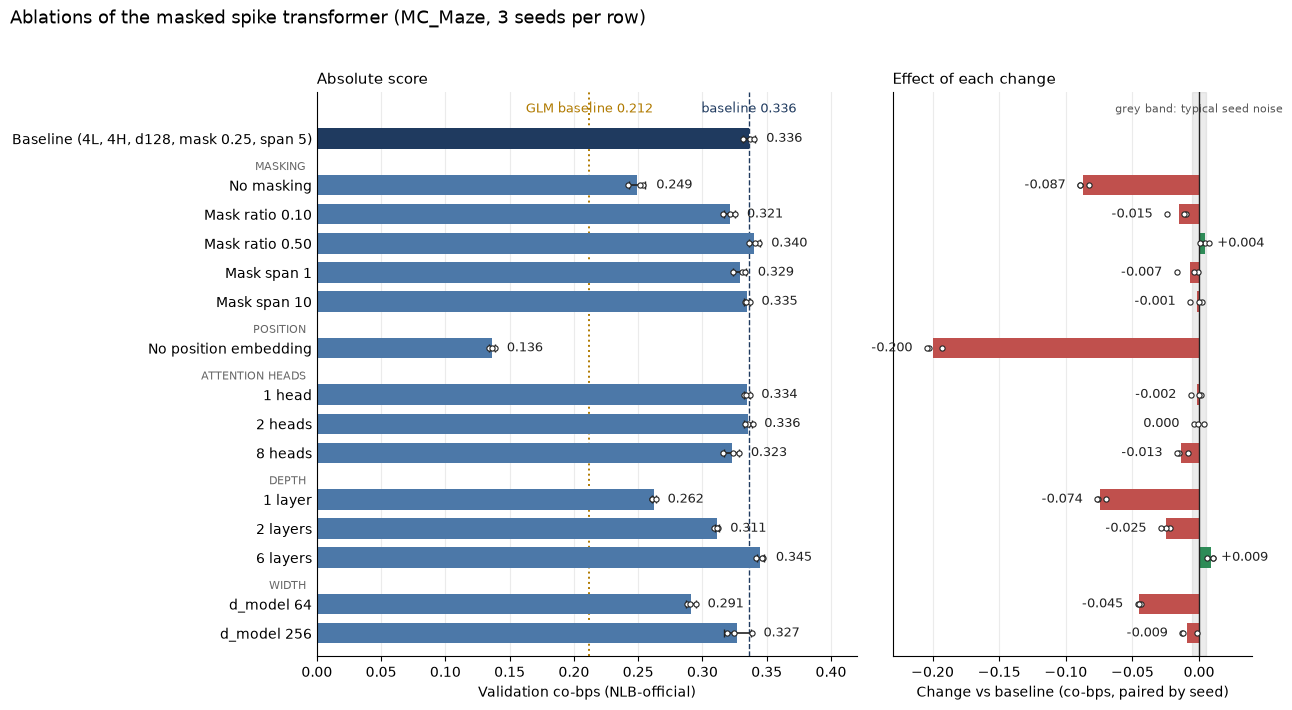

In [2]:
GLM_REF = 0.212   # smoothing + Poisson GLM, NLB reference params (step 5)

order = list(S.keys())                                  # config order from the sweep
y = np.arange(len(order))[::-1].astype(float)
groups = [S[k]["group"] for k in order]
# gap between groups
for i in range(1, len(order)):
    if groups[i] != groups[i - 1]:
        y[i:] -= 0.6

BLUE, DARK, GREY = "#4C78A8", "#1F3A5F", "#222222"
fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 7.2), sharey=True,
                             gridspec_kw={"width_ratios": [1.5, 1]})

for yi, k in zip(y, order):
    s = S[k]
    v = np.array(s["val_per_seed"])
    a0.barh(yi, v.mean(), color=DARK if k == "base" else BLUE, height=0.7, zorder=2)
    a0.errorbar(v.mean(), yi, xerr=v.std(ddof=1), color=GREY, capsize=3, lw=1.2, zorder=4)
    a0.scatter(v, np.full(len(v), yi), s=14, color="white", edgecolor=GREY, lw=0.8, zorder=5)
    a0.text(max(v.max(), v.mean() + v.std(ddof=1)) + 0.009, yi, f"{v.mean():.3f}",
            va="center", fontsize=9, color=GREY)
    d = v - base
    if k != "base":
        a1.barh(yi, d.mean(), color="#C0504D" if d.mean() < 0 else "#2E8B57", height=0.7, zorder=2)
        a1.scatter(d, np.full(len(d), yi), s=14, color="white", edgecolor=GREY, lw=0.8, zorder=5)
        off = 0.006 if d.mean() >= 0 else -0.006
        a1.text(max(d.max(), 0) + 0.006 if d.mean() >= 0 else min(d.min(), 0) - 0.011, yi,
                f"{d.mean() + 0.0:+.3f}".replace("-0.000", "0.000"), va="center", ha="left" if d.mean() >= 0 else "right",
                fontsize=9, color=GREY)

a0.axvline(base.mean(), color=DARK, ls="--", lw=1, zorder=1)
a0.axvline(GLM_REF, color="#B07A00", ls=":", lw=1.4, zorder=1)
a0.text(GLM_REF, y.max() + 0.9, "GLM baseline 0.212", color="#B07A00", fontsize=9, ha="center")
a0.text(base.mean(), y.max() + 0.9, f"baseline {base.mean():.3f}", color=DARK, fontsize=9, ha="center")
a0.set_yticks(y)
a0.set_yticklabels([LABEL[k] for k in order], fontsize=10)
a0.set_xlim(0, 0.42)
a0.set_xlabel("Validation co-bps (NLB-official)")
a0.set_title("Absolute score", loc="left", fontsize=11)

a1.axvline(0, color=GREY, lw=1, zorder=3)
a1.axvspan(-0.005, 0.005, color="#999999", alpha=0.18, zorder=0)
a1.text(0, y.max() + 0.9, "grey band: typical seed noise", fontsize=8, color="#555555", ha="center")
a1.set_xlim(-0.23, 0.04)
a1.set_xlabel("Change vs baseline (co-bps, paired by seed)")
a1.set_title("Effect of each change", loc="left", fontsize=11)

for a in (a0, a1):
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="x", alpha=0.25, zorder=0)
    a.tick_params(axis="y", length=0)
a0.set_ylim(y.min() - 0.8, y.max() + 1.6)

# group labels
for g in dict.fromkeys(groups):
    ys = [yi for yi, gg in zip(y, groups) if gg == g]
    if g != "reference":
        a0.text(-0.02, max(ys) + 0.62, GROUP_TITLE[g].upper(), transform=a0.get_yaxis_transform(),
                fontsize=8, color="#666666", ha="right", va="center")

fig.suptitle("Ablations of the masked spike transformer (MC_Maze, 3 seeds per row)",
             x=0.01, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.96))
Path("../figures").mkdir(exist_ok=True)
fig.savefig("../figures/fig5_ablations.png", dpi=160, bbox_inches="tight", facecolor="white")
plt.show()

## Per-seed paired differences

A change is only worth believing if the sign is the same in every seed and the size clears the noise band.

In [3]:
t = df[df.key != "base"][["config", "delta_mean", "delta_per_seed"]].copy()
t["same sign in all seeds"] = [all(np.sign(x) == np.sign(m) for x in ps)
                               for m, ps in zip(t.delta_mean, t.delta_per_seed)]
t["clears 0.005"] = t.delta_mean.abs() > 0.005
t.round(4).reset_index(drop=True)

,config,delta_mean,delta_per_seed,same sign in all seeds,clears 0.005
0,No masking,-0.0871,"[-0.0891, -0.0829, -0.0892]",True,True
1,Mask ratio 0.10,-0.0150,"[-0.0098, -0.0113, -0.0239]",True,True
2,Mask ratio 0.50,0.0043,"[0.0048, 0.0076, 0.0006]",True,False
3,Mask span 1,-0.0070,"[-0.0006, -0.0037, -0.0168]",True,True
4,Mask span 10,-0.0015,"[0.002, 0.0002, -0.0067]",False,False
5,No position embedding,-0.1999,"[-0.1925, -0.2029, -0.2041]",True,True
6,1 head,-0.0016,"[0.0012, 0.0001, -0.0062]",False,False
7,2 heads,-0.0004,"[0.0039, -0.0039, -0.0012]",False,False
8,8 heads,-0.0134,"[-0.0152, -0.0086, -0.0166]",True,True
9,1 layer,-0.0741,"[-0.0702, -0.0757, -0.0764]",True,True


## What the ablations say

* **Masking is essential** (-0.087 without it). With nothing hidden, held-in reconstruction is an identity task and the model learns little about neural structure.
* **Position information is critical** (0.136 without; below the 0.212 GLM). Attention is order-blind, so without position embeddings the model cannot tell *when* in the trial a bin occurred.
* **Depth helps** monotonically up to the largest model tried (0.262, 0.311, 0.336, 0.345 for 1, 2, 4, 6 layers). The 6-layer gain over baseline is small (+0.009) but its sign is consistent.
* **1, 2 and 4 heads are indistinguishable.** 8 heads is about 0.013 worse in every seed (16-dimensional heads). Multi-head attention is not doing measurable work here.
* **Mask settings** are mostly flat: ratio 0.50 is slightly above 0.25 (+0.004, below the noise band); ratio 0.10 is clearly worse (-0.015); span 1 (-0.007) and span 10 (-0.001) are not reliably different from span 5 (span 1 changes sign across seeds).
* **Width:** 64 is too small (-0.045). 256 is slightly worse than 128 (-0.009, same sign in all 3 seeds) and noisier, at these regularisation settings.

**Caveats**

* Only 3 seeds per row. Borderline calls (mask 0.50, 6 layers, 8 heads) need more seeds before anyone relies on them.
* The baseline's dropout and weight decay were tuned at 4 layers / d_model 128. Larger models may want different regularisation, so "no gain from width 256" means "no gain at these settings".
* These are validation-split numbers. The dev-fold column (table above) ranks the configurations the same way. Any change to the frozen configuration should be chosen on the dev fold and re-run with 5 seeds.